In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt


# =========================================================
# 1. Load augmented training data
# =========================================================

d = torch.load("../../data/augmented/iris_train_features_augmented.pt")
l = torch.load("../../data/augmented/iris_train_labels_augmented.pt")

# Select class 1 and class 2
d1 = d[l == 1]
d2 = d[l == 2]


# =========================================================
# 2. Keep only features 2 and 3
# =========================================================

a = len(d1)
b = len(d2)

x = torch.zeros(
    (a + b, 2),
    dtype=d.dtype
)

x[:a, :] = d1[:, 2:]
x[a:, :] = d2[:, 2:]


# =========================================================
# 3. Create binary labels and shuffle
# =========================================================

y = torch.tensor(
    [0] * a + [1] * b,
    dtype=torch.long
)

# Random permutation
i = torch.randperm(a + b)

x = x[i]
y = y[i]


# =========================================================
# 4. Save training dataset
# =========================================================

torch.save(x, "../../data/train/iris2_train.pt")
torch.save(y, "../../data/train/iris2_train_labels.pt")


# =========================================================
# 5. Load augmented test data
# =========================================================

d = torch.load("../../data/augmented/iris_test_features_augmented.pt")
l = torch.load("../../data/augmented/iris_test_labels_augmented.pt")

# Select class 1 and class 2
d1 = d[l == 1]
d2 = d[l == 2]

a = len(d1)
b = len(d2)

x = torch.zeros(
    (a + b, 2),
    dtype=d.dtype
)

x[:a, :] = d1[:, 2:]
x[a:, :] = d2[:, 2:]


# =========================================================
# 6. Create binary labels and shuffle
# =========================================================

y = torch.tensor(
    [0] * a + [1] * b,
    dtype=torch.long
)

i = torch.randperm(a + b)

x = x[i]
y = y[i]


# =========================================================
# 7. Save test dataset
# =========================================================

torch.save(x, "../../data/test/iris2_test.pt")
torch.save(y, "../../data/test/iris2_test_labels.pt")

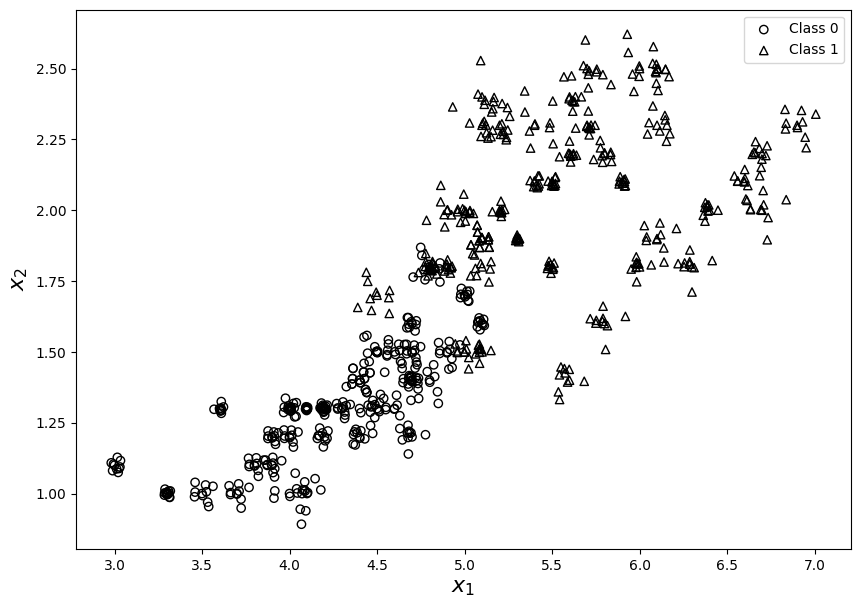

In [ ]:
# Load the binary training dataset
x = torch.load("../../data/train/iris2_train.pt")
y = torch.load("../../data/train/iris2_train_labels.pt")

# Separate the two classes
class0 = x[y == 0]
class1 = x[y == 1]

# Create plot
fig, ax = plt.subplots(figsize=(10, 7))

# Class 0: circles
ax.scatter(
    class0[:, 0].numpy(),
    class0[:, 1].numpy(),
    marker="o",
    facecolors="none",
    edgecolors="black",
    label="Class 0"
)

# Class 1: triangles
ax.scatter(
    class1[:, 0].numpy(),
    class1[:, 1].numpy(),
    marker="^",
    facecolors="none",
    edgecolors="black",
    label="Class 1"
)

# Labels
ax.set_xlabel("$x_1$", fontsize=16)
ax.set_ylabel("$x_2$", fontsize=16)

ax.legend()

plt.show()